# Semantic Segmentation

---

## Dataset Preparation

In [1]:
# Setup

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from tensorflow.keras.models import Model

data_dir = Path.cwd() / "data"

In [2]:
# Collecting image paths

records = []

for image_path in sorted(data_dir.glob("*/*.tif")):
    # Skipping masks, saving image and mask together
    if image_path.stem.endswith("_mask"):
        continue

    # Gettings mask patah from image name
    mask_path = image_path.with_name(f"{image_path.stem}_mask.tif")
    if not mask_path.is_file():
        raise FileNotFoundError(f"Missing mask: {mask_path}")

    records.append(
        {
            "patient_id": image_path.parent.name,  # Patient id is folder name i think
            "image_id": image_path.stem,
            "image_path": str(image_path),
            "mask_path": str(mask_path),
        }
    )

In [3]:
# Converting to pandas

data_df = pd.DataFrame(records)
print(f"Number of patients: {data_df['patient_id'].nunique()}")
print(f"Number of image-mask pairs: {len(data_df)}")

display(data_df.head())

Number of patients: 110
Number of image-mask pairs: 3929


,patient_id,image_id,image_path,mask_path
0,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_1,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...
1,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_10,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...
2,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_11,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...
3,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_12,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...
4,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_13,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...


In [4]:
# Inspecting images

# Grabbing first pair of images
sample = data_df.iloc[0]
with Image.open(sample["image_path"]) as image_file:
    image = np.array(image_file)
with Image.open(sample["mask_path"]) as mask_file:
    mask = np.array(mask_file)
    
print(f"Image shape: {image.shape}")
print(f"Image data type: {image.dtype}")
print(f"Image pixel range: {image.min()} to {image.max()}")

print(f"\nMask shape: {mask.shape}")
print(f"Mask data type: {mask.dtype}")
print(f"Unique mask values: {np.unique(mask)}")

Image shape: (256, 256, 3)
Image data type: uint8
Image pixel range: 0 to 215

Mask shape: (256, 256)
Mask data type: uint8
Unique mask values: [0]


In [5]:
# Identifying any images with abnormalities from masks
# If any white pixels in mask, abnormalities present

has_abnormality = []

for mask_path in data_df["mask_path"]:
    with Image.open(mask_path) as mask_file:
        mask = np.array(mask_file)
        
    has_abnormality.append(bool(np.any(mask > 0))) # If any are non zero
    
data_df["has_abnormality"] = has_abnormality

print(f"Masks with abnormalities found:    {data_df['has_abnormality'].sum()}")
print(f"Masks without abnormalities found: {(~data_df['has_abnormality']).sum()}")

Masks with abnormalities found:    1373
Masks without abnormalities found: 2556


In [6]:
# Final Dataset Inspection
# Images will be loaded from paths as needed for memory

display(data_df.head())
display(data_df.describe())

,patient_id,image_id,image_path,mask_path,has_abnormality
0,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_1,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,False
1,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_10,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,False
2,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_11,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,True
3,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_12,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,True
4,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_13,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,True


,patient_id,image_id,image_path,mask_path,has_abnormality
count,3929,3929,3929,3929,3929
unique,110,3929,3929,3929,2
top,TCGA_HT_A61A_20000127,TCGA_CS_4941_19960909_1,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,False
freq,88,1,1,1,2556


## Data visualization

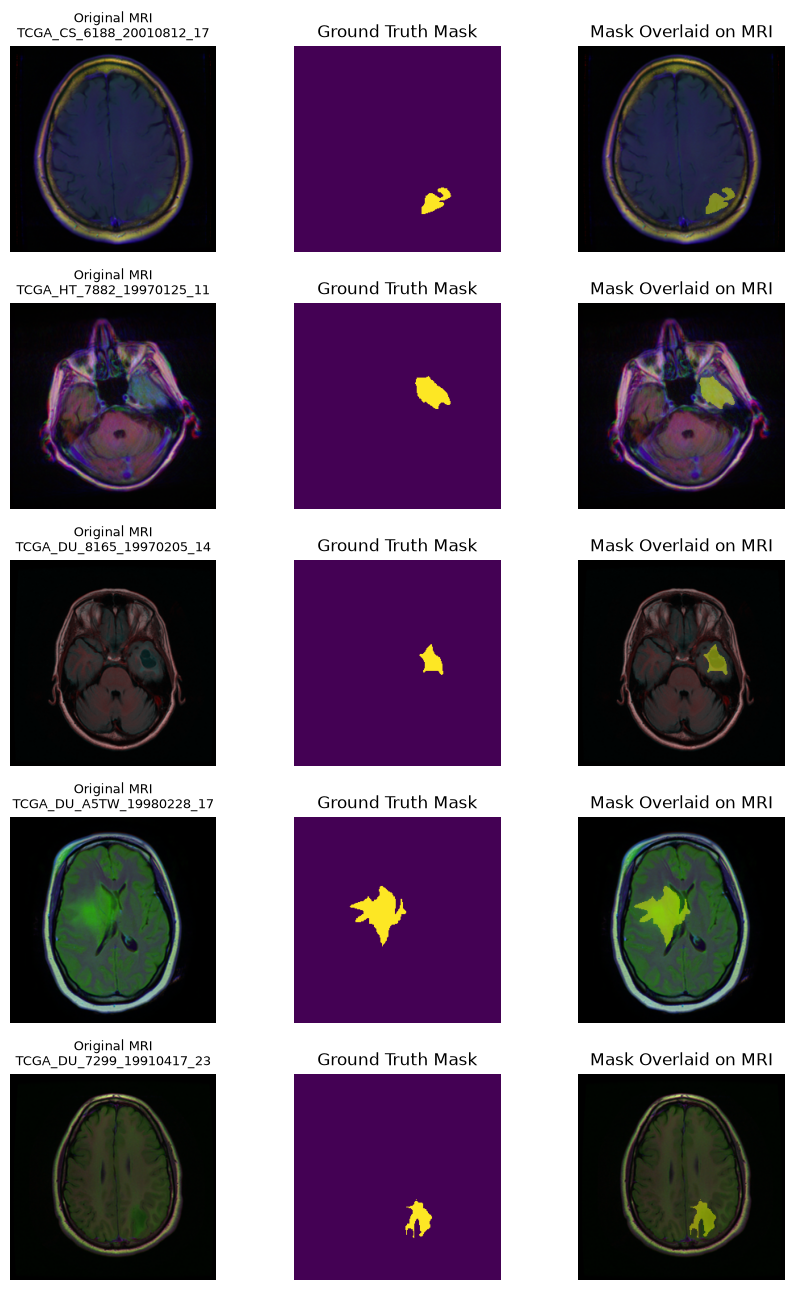

In [7]:
# Viewing images and their masks

# Getting all rows where mask has abnormality
abnormal_masks = data_df[data_df["has_abnormality"]]

examples = (
    abnormal_masks
    .groupby("patient_id", group_keys=False) # Group rows by patient
    .sample(n=1, random_state=24)            # Choose one mask from each patient
    .sample(n=5, random_state=24)            # Choose 5 masks from the last result
)

fig, axes = plt.subplots(5, 3, figsize=(9, 13))
for row_idx, (_, sample) in enumerate(examples.iterrows()):
    # Loading original images
    with Image.open(sample["image_path"]) as image_file:
        image = np.array(image_file)
    with Image.open(sample["mask_path"]) as mask_file:
            mask = np.array(mask_file)
            
    # Display original
    axes[row_idx, 0].imshow(image)
    axes[row_idx, 0].set_title(
        f"Original MRI\n{sample['image_id']}", fontsize=9
    )
    
    # Display mask
    axes[row_idx, 1].imshow(mask)
    axes[row_idx, 1].set_title("Ground Truth Mask")
    
    # Display overlaid
    
    # Hiding bg pixels so they don't cover image
    binary_mask = mask > 0
    overlay_mask = np.ma.masked_where(~binary_mask, binary_mask)
    
    axes[row_idx, 2].imshow(image)
    axes[row_idx, 2].imshow(
        overlay_mask,
        cmap="autumn",
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    axes[row_idx, 2].set_title("Mask Overlaid on MRI")
    
    for axis in axes[row_idx]:
        axis.axis("off")
        
plt.tight_layout()
plt.show()

## Dataset Preprocessing

In [8]:
# Splitting into training, validation and test

# Splitting data based on patients rather than images
# 70% training, 15% validation, 15% test
patient_ids = np.array(sorted(data_df["patient_id"].unique()))
rng = np.random.default_rng(seed=24) # Need to be able to reproduce splits
rng.shuffle(patient_ids)

# Calculating splits
train_end = int(0.70 * len(patient_ids))
val_end = train_end + int(0.15 * len(patient_ids))

train_patient_ids = patient_ids[:train_end]
val_patient_ids = patient_ids[train_end:val_end]
test_patient_ids = patient_ids[val_end:]

# Assign all images to set containing their patient
train_df = (
    data_df[data_df["patient_id"].isin(train_patient_ids)].copy().reset_index(drop=True)
)
val_df = (
    data_df[data_df["patient_id"].isin(val_patient_ids)].copy().reset_index(drop=True)
)
test_df = (
    data_df[data_df["patient_id"].isin(test_patient_ids)].copy().reset_index(drop=True)
)

# Check that no patient appears in more than one df
if(
    not set(train_patient_ids).isdisjoint(val_patient_ids)
    or not set(train_patient_ids).isdisjoint(test_patient_ids)
    or not set(val_patient_ids).isdisjoint(test_patient_ids)
):
    raise ValueError("A patient appears in more than one set.")

# Looking at the splits
split_summary = pd.DataFrame(
    [
        {
            "split": name,
            "patients": frame["patient_id"].nunique(),
            "slices": len(frame),
            "slices_with_abnormality": frame["has_abnormality"].sum(),
            "abnormality_percentage": round(frame["has_abnormality"].mean() * 100, 1),
        }
        for name, frame in [
            ("Training", train_df),
            ("Validation", val_df),
            ("Test", test_df),
        ]
    ]
)
display(split_summary)

,split,patients,slices,slices_with_abnormality,abnormality_percentage
0,Training,77,2792,982,35.2
1,Validation,16,492,179,36.4
2,Test,17,645,212,32.9


In [9]:
# Preparing image mask pairs

def load_images(image_path, mask_path):
    """Preps image and mask pair for augmentation"""
    with Image.open(image_path) as image_file:
        image = np.array(image_file).astype(np.float32)
        
    # Making sure mask is binary floats
    with Image.open(mask_path) as mask_file:
        mask = (np.array(mask_file) > 0).astype(np.float32)
    # Adding a channel for model output
    mask = mask[..., np.newaxis]
    
    # Could resize but i don't think needed for this dataset
        
    return image, mask
    
sample = train_df.iloc[0]
image,mask = load_images(sample["image_path"], sample["mask_path"])
print(f"Image shape: {image.shape}, dtype: {image.dtype}")
print(f"Image range: {image.min():.3f} to {image.max():.3f}")
print(f"Mask shape: {mask.shape}, dtype: {mask.dtype}")
print(f"Mask values: {np.unique(mask)}")


Image shape: (256, 256, 3), dtype: float32
Image range: 0.000 to 215.000
Mask shape: (256, 256, 1), dtype: float32
Mask values: [0.]


In [10]:
# Augmentation

# Need to augment image and mask the same way
aug_settings = {
    "rotation_range" : 15,
    "width_shift_range" : 0.05,
    "height_shift_range" : 0.05,
    "zoom_range" : 0.10,
    "horizontal_flip" : True,
    "fill_mode" : "constant",
    "cval" : 0.0
}

image_gen = ImageDataGenerator(
    **aug_settings,
    rescale=1.0 / 255.0, # Change pixel vals to 0 - 1
    interpolation_order = 1
)

mask_gen = ImageDataGenerator(
    **aug_settings,
    interpolation_order = 0
)

Augmented image range: 0.000 to 0.929
Augmented mask values: [0. 1.]


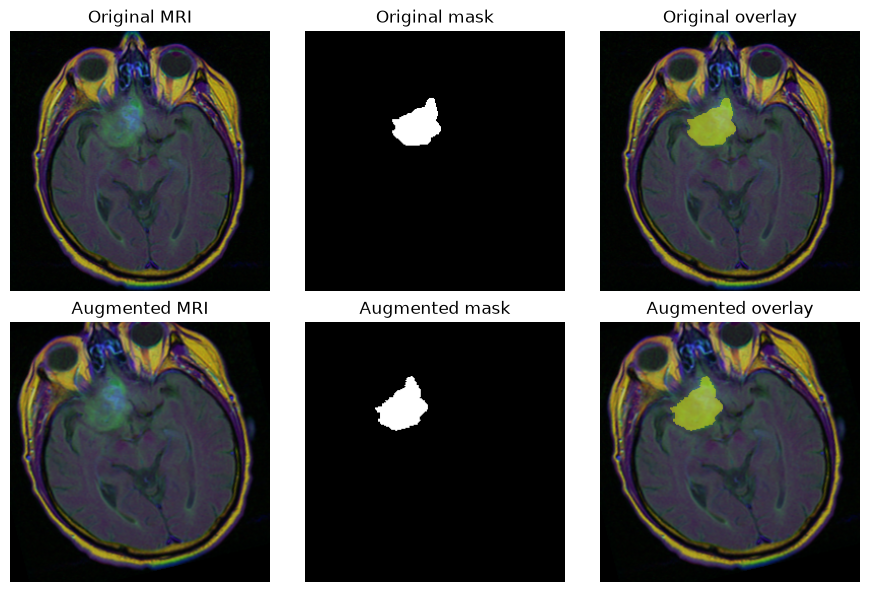

In [11]:
# Checking augmentation can be done to image and mask correctly

# Getting sample with an abnormality
sample = train_df[train_df["has_abnormality"]].iloc[0]
image, mask = load_images(sample["image_path"], sample["mask_path"])

# Getting one transform and applying to both
transform = image_gen.get_random_transform(image.shape, seed=24)
aug_image = image_gen.apply_transform(image.copy(), transform)
aug_mask = mask_gen.apply_transform(mask.copy(), transform)

# Rescale after 
aug_image = image_gen.standardize(aug_image)

print(f"Augmented image range: {aug_image.min():.3f} to {aug_image.max():.3f}")
print(f"Augmented mask values: {np.unique(aug_mask)}")

# Visualization
pairs = [
    (image / 255, mask, "Original"),
    (aug_image, aug_mask, "Augmented")
]

fig, axes = plt.subplots(2,3, figsize = (9, 6))
for row, (display_image, display_mask, label) in enumerate(pairs):
    binary_mask = display_mask[:,:,0] > 0
    
    axes[row, 0].imshow(display_image)
    axes[row, 0].set_title(f"{label} MRI")
    
    axes[row, 1].imshow(binary_mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title(f"{label} mask")
    
    overlay = np.ma.masked_where(~binary_mask, binary_mask)
    axes[row, 2].imshow(display_image)
    axes[row, 2].imshow(overlay, cmap="autumn", alpha=0.45, vmin=0, vmax=1)
    axes[row, 2].set_title(f"{label} overlay")
    
    for axis in axes[row]:
        axis.axis("off")
        
        
plt.tight_layout()
plt.show()

In [12]:
# Batch loader for training and eval

class SegmentationDataset(tf.keras.utils.PyDataset): # Keras can use this
    def __init__(
        self, dataframe, image_generator, mask_generator,
        batch_size=8, augment=False, shuffle=False, seed=24
    ):
        super().__init__()
        
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.image_generator = image_generator
        self.mask_generator = mask_generator
        self.batch_size = batch_size
        self.augment = augment
        self.shuffle = shuffle
        self.rng = np.random.default_rng(seed)
        self.indices = np.arange(len(self.dataframe))
        
        # Suffling
        if self.shuffle:
            self.rng.shuffle(self.indices)
        
    def __len__(self):
        """Get number of batches"""
        return(len(self.dataframe) + self.batch_size - 1) // self.batch_size
    
    def __getitem__(self, batch_index):
        """Load and prep image mask pairs for one batch"""
        start = batch_index * self.batch_size
        batch_indices = self.indices[start:start + self.batch_size]
        images, masks = [], []
        
        for index in batch_indices:
            sample = self.dataframe.iloc[index]
            image,mask = load_images(
                sample["image_path"], sample["mask_path"]
            )
            
            # Apply same transformes to mask and image
            if self.augment:
                transform = self.image_generator.get_random_transform(
                    image.shape
                )
                image = self.image_generator.apply_transform(image, transform)
                mask = self.mask_generator.apply_transform(mask, transform)
                
            image = self.image_generator.standardize(image)
            mask = self.mask_generator.standardize(mask)
            
            images.append(image)
            masks.append(mask)
        
        return np.stack(images), np.stack(masks)
    
    def on_epoch_end(self):
        """If set to shuffle, will shuffle after each complete pass of dataset."""
        if self.shuffle:
            self.rng.shuffle(self.indices)

In [13]:
# Training set loader

tf.keras.utils.set_random_seed(24)

train_dataset = SegmentationDataset(
    train_df,
    image_gen,
    mask_gen,
    batch_size=8,
    augment=True,
    shuffle=True
)

# Looking at a batch
batch_images, batch_masks = train_dataset[0]
print(f"Training batches: {len(train_dataset)}")
print(f"Image batch shape: {batch_images.shape}")
print(f"Mask batch shape: {batch_masks.shape}")
print(f"Image range: {batch_images.min()} to {batch_images.max()}")
print(f"Mask values: {np.unique(batch_masks)}")

Training batches: 349
Image batch shape: (8, 256, 256, 3)
Mask batch shape: (8, 256, 256, 1)
Image range: 0.0 to 0.9777360558509827
Mask values: [0. 1.]


In [14]:
# Validation dataset and augmentation

# Use these for no augmentation
eval_image_gen = ImageDataGenerator(rescale=1.0 / 255.0)
eval_mask_gen = ImageDataGenerator()

# Keeping unchanged images for early stopping 
val_dataset = SegmentationDataset(
    val_df,
    eval_image_gen,
    eval_mask_gen,
    batch_size=8,
    augment=False,
    shuffle=False
)

# Augmented version, going to do seperate test on both val sets
# as aug will change so results will be different each time
augmented_val_dataset = SegmentationDataset(
    val_df,
    image_gen,
    mask_gen,
    batch_size=8,
    augment=True,
    shuffle=False
)

# Test dataset is unchanged, just reusing same class, needs generators
test_dataset = SegmentationDataset(
    test_df,
    eval_image_gen,
    eval_mask_gen,
    batch_size=8,
    augment=False,
    shuffle=False
)

print(f"Validation batches: {len(val_dataset)}")
print(f"Augmented validation batches: {len(augmented_val_dataset)}")
print(f"Test batches: {len(test_dataset)}")


Validation batches: 62
Augmented validation batches: 62
Test batches: 81


## Model Designs

### Custom Model

In [15]:
# Custom autoencoder

# Model layout:
# input 256 -> 128 -> 64 -> bottleneck 32 -> 64 -> 128 -> restored 256 -> 1 abnormality prob per pixel

input_shape = (256, 256, 3)
input_layer = Input(shape=input_shape)

# Shrinking down
encoding_layer = Conv2D(16, 3, activation="relu", padding="same")(input_layer)
encoding_layer = MaxPooling2D(2)(encoding_layer)

encoding_layer = Conv2D(32, 3, activation="relu", padding="same")(encoding_layer)
encoding_layer = MaxPooling2D(2)(encoding_layer)

encoding_layer = Conv2D(64, 3, activation="relu", padding="same")(encoding_layer)
encoding_layer = MaxPooling2D(2)(encoding_layer)

# Bottleneck at 32x32
bottleneck_layer = Conv2D(128, 3, activation="relu", padding="same")(encoding_layer)

# Going back up
decoding_layer = UpSampling2D(2)(bottleneck_layer)
decoding_layer = Conv2D(64, 3, activation="relu", padding="same")(decoding_layer)

decoding_layer = UpSampling2D(2)(decoding_layer)
decoding_layer = Conv2D(32, 3, activation="relu", padding="same")(decoding_layer)

decoding_layer = UpSampling2D(2)(decoding_layer)
decoding_layer = Conv2D(16, 3, activation="relu", padding="same")(decoding_layer)

# Prediction
output_layer = Conv2D(1, 1, activation="sigmoid", padding="same")(decoding_layer)

# Put model together
custom_autoencoder = Model(input_layer, output_layer)
custom_autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 128, 128, 32)   │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 256, 256, 16)   │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 256, 256, 1)    │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 194,337 (759.13 KB)

 Trainable params: 194,337 (759.13 KB)

 Non-trainable params: 0 (0.00 B)

### Pretrained Model

In [16]:
# Base pretrained model

pretrained_base_model = tf.keras.applications.MobileNetV2(
    input_shape=(256, 256, 3),
    include_top=False,
    weights="imagenet"
)

# Using models already learned features
pretrained_base_model.trainable = False

pretrained_base_model.summary()

C:\Users\foste\AppData\Local\Temp\ipykernel_13224\2826889179.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  pretrained_base_model = tf.keras.applications.MobileNetV2(


Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 128, 128,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 128, 128,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 128, 128,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 128, 128,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 128, 128,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 128, 128,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 128, 128,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 128, 128,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 129, 129,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 64, 64,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 64, 64,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 64, 64,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 64, 64,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [17]:
# Creating encoder from pretrained model weights

# Layers we are grabbing outputs from
layer_names = [
    "block_1_expand_relu",  # 128 x 128
    "block_3_expand_relu",  # 64 x 64
    "block_6_expand_relu",  # 32 x 32
    "block_13_expand_relu", # 16 x 16
    "block_16_project",     # 8 x 8 Bottleneck
]

# Outputs from layers for skip connections and bottleneck
encoder_outputs = [
    pretrained_base_model.get_layer(name).output
    for name in layer_names
]

# Build the encoder
pretrained_encoder = tf.keras.Model(
    inputs=pretrained_base_model.input,
    outputs=encoder_outputs,
    name= "pretrained_encoder"
)

# Freeze pretrained weights
pretrained_encoder.trainable = False

# Checking encoder output shapes
for name, output in zip(layer_names, pretrained_encoder.outputs):
    print(f"{name}: {output.shape}")

input_layer = tf.keras.layers.Input(shape=(256, 256, 3))

# Rescale to expected input for MobileNetV2
encoder_input = tf.keras.layers.Rescaling(
    scale=2.0,
    offset=-1.0
)(input_layer)

# Connect input to the encoder
skip_1, skip_2, skip_3, skip_4, bottleneck = pretrained_encoder(
    encoder_input,
    training=False
)

block_1_expand_relu: (None, 128, 128, 96)
block_3_expand_relu: (None, 64, 64, 144)
block_6_expand_relu: (None, 32, 32, 192)
block_13_expand_relu: (None, 16, 16, 576)
block_16_project: (None, 8, 8, 320)


In [18]:
# Decoder


# First decoder block
# Upsample bottle neck to 16x16
decoding_layer = tf.keras.layers.Conv2DTranspose(
    filters=512,
    kernel_size=3,
    strides=2,
    padding="same",
    use_bias=False
)(bottleneck)
decoding_layer = tf.keras.layers.BatchNormalization()(decoding_layer)
decoding_layer = tf.keras.layers.Activation("relu")(decoding_layer)
# Join upsample with encoders skip connections
decoding_layer = tf.keras.layers.Concatenate()(
    [decoding_layer, skip_4]
)

# 16x16 to 32x32
decoding_layer = tf.keras.layers.Conv2DTranspose(
    filters=256,
    kernel_size=3,
    strides=2,
    padding="same",
    use_bias=False
)(decoding_layer)
decoding_layer = tf.keras.layers.BatchNormalization()(decoding_layer)
decoding_layer = tf.keras.layers.Activation("relu")(decoding_layer)
decoding_layer = tf.keras.layers.Concatenate()(
    [decoding_layer, skip_3]
)

# 32x32 to 64x64
decoding_layer = tf.keras.layers.Conv2DTranspose(
    filters=128,
    kernel_size=3,
    strides=2,
    padding="same",
    use_bias=False
)(decoding_layer)
decoding_layer = tf.keras.layers.BatchNormalization()(decoding_layer)
decoding_layer = tf.keras.layers.Activation("relu")(decoding_layer)
# Join upsample with encoders skip connections
decoding_layer = tf.keras.layers.Concatenate()(
    [decoding_layer, skip_2]
)

# 64x64 to 128x128
decoding_layer = tf.keras.layers.Conv2DTranspose(
    filters=64,
    kernel_size=3,
    strides=2,
    padding="same",
    use_bias=False
)(decoding_layer)
decoding_layer = tf.keras.layers.BatchNormalization()(decoding_layer)
decoding_layer = tf.keras.layers.Activation("relu")(decoding_layer)
# Join upsample with encoders skip connections
decoding_layer = tf.keras.layers.Concatenate()(
    [decoding_layer, skip_1]
)

# 128x128 to 256x256, Final restoration with probability prediction per pixel
output_layer = tf.keras.layers.Conv2DTranspose(
    filters=1,
    kernel_size=3,
    strides=2,
    padding="same",
    activation="sigmoid"
)(decoding_layer)

In [19]:
# Assembling full u-net from decoder and encoder

pretrained_unet_model = tf.keras.Model(
    inputs=input_layer,
    outputs=output_layer,
    name="mobilenetv2_unet"
)

pretrained_unet_model.summary()

Model: "mobilenetv2_unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 256, 256,  │          0 │ input_layer_2[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pretrained_encoder  │ [(None, 128, 128, │  1,841,984 │ rescaling[0][0]   │
│ (Functional)        │ 96), (None, 64,   │            │                   │
│                     │ 64, 144), (None,  │            │                   │
│                     │ 32, 32, 192),     │            │                   │
│                     │ (None, 16, 16,    │            │                   │
│                     │ 576), (None, 8,   │            │                   │
│                     │ 8, 320)]          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 16, 16,    │  1,474,560 │ pretrained_encod… │
│ (Conv2DTranspose)   │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 16, 16,    │      2,048 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ activation[0][0], │
│ (Concatenate)       │ 1088)             │            │ pretrained_encod… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 32, 32,    │  2,506,752 │ concatenate[0][0] │
│ (Conv2DTranspose)   │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │      1,024 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 32, 32,    │          0 │ activation_1[0][… │
│ (Concatenate)       │ 448)              │            │ pretrained_encod… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_2  │ (None, 64, 64,    │    516,096 │ concatenate_1[0]… │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 64, 64,    │          0 │ activation_2[0][… │
│ (Concatenate)       │ 272)              │            │ pretrained_encod

 Total params: 6,501,345 (24.80 MB)

 Trainable params: 4,657,441 (17.77 MB)

 Non-trainable params: 1,843,904 (7.03 MB)

## Model Training

In [20]:
# Loss functions

# Dice
# def dice_coefficient(y_true, y_pred):
#     y_true = tf.cast(y_true, tf.float32)
#     y_pred = tf.cast(y_pred, tf.float32)  
#     axes = (1,2,3)
#     intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
#     total = (
#         tf.reduce_sum(y_true, axis=axes)
#         + tf.reduce_sum(y_pred, axis=axes)
#     )  
#     # Handle div by 0 and empty masks
#     # Empty mask with no abnormality overlap is always 0
#     # adding 1 to both sides gives dice = 1 when both masks are empty, giving signal still
#     smooth = 1.0
#     return (2.0 * intersection + smooth) / (total + smooth)

# def dice_loss(y_true, y_pred):
#     return 1.0 - dice_coefficient(y_true, y_pred)

dice_loss = tf.keras.losses.Dice(axis=None)

# Tversky
def tversky_index(y_true, y_pred, alpha=0.3, beta=0.7):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    
    axes = (None) # Across batch not image
    tp = tf.reduce_sum(y_true * y_pred, axis=axes)
    fp = tf.reduce_sum((1.0 - y_true) * y_pred, axis=axes)
    fn = tf.reduce_sum(y_true * (1.0 - y_pred), axis=axes)
    
    # Handling div by 0 and empty mask
    smooth = 1.0
    return (tp + smooth) / (tp + alpha * fp + beta * fn + smooth)

def tversky_loss(y_true, y_pred):
    return 1.0 - tversky_index(y_true, y_pred)

def focal_tversky_loss(y_true, y_pred):
    loss = tversky_loss(y_true, y_pred)
    loss = tf.clip_by_value(loss, 1e-7, 1.0)
    return tf.pow(loss, 0.75)

### Custom Models

In [21]:
model_dir = Path.cwd() / "models"
history_dir = Path.cwd() / "history"
model_dir.mkdir(exist_ok=True)
history_dir.mkdir(exist_ok=True)

# Keeping starting weights for the different loss models
if not (model_dir/"custom_initial.weights.h5").exists():
    custom_autoencoder.save_weights(model_dir / "custom_initial.weights.h5")

In [22]:
# Custom dice loss model

custom_autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=dice_loss,
    metrics=[tf.keras.metrics.BinaryAccuracy(name="pixel_accuracy")]
)

# Early stopping when no improvement in 8 epochs
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    mode="min",
    restore_best_weights=True
)

# Saving whe nloss improves
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(model_dir / "custom_dice.keras"),
    monitor="val_loss",
    mode="min",
    save_best_only=True
)

# Logging results
csv_logger = tf.keras.callbacks.CSVLogger(str(history_dir/"custom_dice.csv"))

In [23]:
# Training dice model

# Train only if file doesnt exist
if not (model_dir/"custom_dice.keras").exists():
    custom_autoencoder.load_weights(
        model_dir/"custom_initial.weights.h5"
    )
    
    history_custom_dice = custom_autoencoder.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=50,
        callbacks=[early_stopping, checkpoint, csv_logger],
        shuffle=False
    )
# Otherwise load trained model and history
else:
    custom_autoencoder = tf.keras.models.load_model(
        model_dir/"custom_dice.keras",
        compile=False
    )
    history_custom_dice = tf.keras.callbacks.History()
    history_custom_dice.history = (
        pd.read_csv(history_dir/"custom_dice.csv")
        .drop(columns="epoch")
        .to_dict("list")
    )
    print("Loaded saved dice model and history")

Loaded saved dice model and history


In [24]:
# Tversky model

if not (model_dir/"custom_tversky.keras").exists():
    custom_tversky = tf.keras.models.clone_model(custom_autoencoder)
    custom_tversky.load_weights(model_dir/"custom_initial.weights.h5")

    custom_tversky.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss=tversky_loss,
        metrics = [tf.keras.metrics.BinaryAccuracy(name="pixel_accuracy")]
    )

    # Early stopping when no improvement in 8 epochs
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        mode="min",
        restore_best_weights=True
    )

    # Saving when loss improves
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=str(model_dir / "custom_tversky.keras"),
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )

    # Logging results
    csv_logger = tf.keras.callbacks.CSVLogger(str(history_dir/"custom_tversky.csv"))

    # Train
    history_custom_tversky = custom_tversky.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=50,
        callbacks=[early_stopping, checkpoint, csv_logger],
        shuffle=False
    )

else:
    # load already saved stuff
    custom_tversky = tf.keras.models.load_model(
        model_dir/"custom_tversky.keras",
        compile=False
    )
    history_custom_tversky = tf.keras.callbacks.History()
    history_custom_tversky.history = (
    pd.read_csv(history_dir/"custom_tversky.csv")
    .drop(columns="epoch")
    .to_dict("list"))
    
    print("Loaded saved tversky model and history")

Loaded saved tversky model and history


In [25]:
# Focal Tversky model

if not (model_dir/"custom_focal_tversky.keras").exists():
    custom_focal_tversky = tf.keras.models.clone_model(custom_autoencoder)
    custom_focal_tversky.load_weights(model_dir/"custom_initial.weights.h5")

    custom_focal_tversky.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss=focal_tversky_loss,
        metrics = [tf.keras.metrics.BinaryAccuracy(name="pixel_accuracy")]
    )

    # Early stopping when no improvement in 8 epochs
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        mode="min",
        restore_best_weights=True
    )

    # Saving when loss improves
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=str(model_dir / "custom_focal_tversky.keras"),
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )

    # Logging results
    csv_logger = tf.keras.callbacks.CSVLogger(str(history_dir/"custom_focal_tversky.csv"))

    # Train
    history_custom_focal_tversky = custom_focal_tversky.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=50,
        callbacks=[early_stopping, checkpoint, csv_logger],
        shuffle=False
    )

else:
    # load already saved stuff
    custom_focal_tversky = tf.keras.models.load_model(
        model_dir/"custom_focal_tversky.keras",
        compile=False
    )
    history_custom_focal_tversky = tf.keras.callbacks.History()
    history_custom_focal_tversky.history = (
    pd.read_csv(history_dir/"custom_focal_tversky.csv")
    .drop(columns="epoch")
    .to_dict("list"))
    
    print("Loaded saved tversky model and history")

Loaded saved tversky model and history


### Pretrained Models

In [26]:
# Saving initial weights for training all three loss models on same weights

unet_initial_path = model_dir/"pretrained_unet_initial.weights.h5"

if not unet_initial_path.exists():
    pretrained_unet_model.save_weights(unet_initial_path)
    print("Saved initial weights.")
else:
    pretrained_unet_model.load_weights(unet_initial_path)
    print("Loaded initial weights")

Loaded initial weights


In [27]:
# Training with Dice loss


unet_dice_path = model_dir/"pretrained_unet_dice.keras"
unet_dice_history_path = history_dir/"pretrained_unet_dice.csv"

if not (unet_dice_path).exists():
    pretrained_unet_dice_model = tf.keras.models.clone_model(pretrained_unet_model)
    
    # Starting from saved initial weights
    pretrained_unet_dice_model.load_weights(unet_initial_path)
    
    pretrained_unet_dice_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss=dice_loss,
        metrics=[tf.keras.metrics.BinaryAccuracy(name="pixel_accuracy")]
    )
    
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        mode="min",
        restore_best_weights=True
    )
    
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=unet_dice_path,
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )
    
    csv_logger = tf.keras.callbacks.CSVLogger(
        
        str(unet_dice_history_path)
    )
    
    history_unet_dice = pretrained_unet_dice_model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=50,
        callbacks=[early_stopping, checkpoint, csv_logger],
        shuffle=False
    )
    
    pretrained_unet_dice_model.load_weights(unet_dice_path) # Restore best iteration

else:
    # Loading best model
    pretrained_unet_dice_model = tf.keras.models.load_model(
        unet_dice_path,
        compile=False
    )
    history_unet_dice = tf.keras.callbacks.History()
    history_unet_dice.history = (
        pd.read_csv(unet_dice_history_path)
        .drop(columns="epoch")
        .to_dict("list")
    )
    
    print("Loaded saved pretrained unet dice model.")

Loaded saved pretrained unet dice model.


In [28]:
# Training with Tversky loss

unet_tversky_path = model_dir/"pretrained_unet_tversky.keras"
unet_tversky_history_path = history_dir/"pretrained_unet_tversky.csv"

if not (unet_tversky_path).exists():
    pretrained_unet_tversky_model = tf.keras.models.clone_model(pretrained_unet_model)
    
    # Starting from saved initial weights
    pretrained_unet_tversky_model.load_weights(unet_initial_path)
    
    pretrained_unet_tversky_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss=tversky_loss,
        metrics=[tf.keras.metrics.BinaryAccuracy(name="pixel_accuracy")]
    )
    
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        mode="min",
        restore_best_weights=True
    )
    
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=unet_tversky_path,
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )
    
    csv_logger = tf.keras.callbacks.CSVLogger(
        
        str(unet_tversky_history_path)
    )
    
    history_unet_tversky = pretrained_unet_tversky_model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=50,
        callbacks=[early_stopping, checkpoint, csv_logger],
        shuffle=False
    )
    
    pretrained_unet_tversky_model.load_weights(unet_tversky_path) # Restore best iteration

else:
    # Loading best model
    pretrained_unet_tversky_model = tf.keras.models.load_model(
        unet_tversky_path,
        compile=False
    )
    history_unet_tversky = tf.keras.callbacks.History()
    history_unet_tversky.history = (
        pd.read_csv(unet_tversky_history_path)
        .drop(columns="epoch")
        .to_dict("list")
    )
    
    print("Loaded saved pretrained unet tversky model.")

Loaded saved pretrained unet tversky model.


In [29]:
# Training with focal Tversky loss

unet_focal_tversky_path = model_dir/"pretrained_unet_focal_tversky.keras"
unet_focal_tversky_history_path = history_dir/"pretrained_unet_focal_tversky.csv"

if not (unet_focal_tversky_path).exists():
    pretrained_unet_focal_tversky_model = tf.keras.models.clone_model(pretrained_unet_model)

    # Starting from saved initial weights
    pretrained_unet_focal_tversky_model.load_weights(unet_initial_path)
    
    pretrained_unet_focal_tversky_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss=focal_tversky_loss,
        metrics=[tf.keras.metrics.BinaryAccuracy(name="pixel_accuracy")]
    )
    
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        mode="min",
        restore_best_weights=True
    )
    
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=unet_focal_tversky_path,
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )
    
    csv_logger = tf.keras.callbacks.CSVLogger(
        
        str(unet_focal_tversky_history_path)
    )
    
    history_unet_focal_tversky = pretrained_unet_focal_tversky_model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=50,
        callbacks=[early_stopping, checkpoint, csv_logger],
        shuffle=False
    )
    
    pretrained_unet_focal_tversky_model.load_weights(unet_focal_tversky_path) # Restore best iteration

else:
    # Loading best model
    pretrained_unet_focal_tversky_model = tf.keras.models.load_model(
        unet_focal_tversky_path,
        compile=False
    )
    history_unet_focal_tversky = tf.keras.callbacks.History()
    history_unet_focal_tversky.history = (
        pd.read_csv(unet_focal_tversky_history_path)
        .drop(columns="epoch")
        .to_dict("list")
    )
    
    print("Loaded saved pretrained unet focal tversky model.")

Loaded saved pretrained unet focal tversky model.


## Model Evaluation

The first comparison table is based on validation pixel accuracy at the epoch with the lowest validation loss. The graphs show training and validation loss across epochs.

I have chosen to compare the validation pixel accuracy as it is common across all models, comparing raw loss directly would be incorrect as the different loss functions have different scales. One downside to using validation pixel accuracy is that the large number of background pixels can produce a high accuracy even when the segmentation is poor.

This provides us a base for comparison but further comparisons with the test set will be made using ACC, Dice and Jaccard alongside the predicted masks to assess how good the segmentation is.

Final evaluations will be made after tuning on best found configs for both model groups. (Found at end of notebook)

Validation pixel accuracy at best checkpoint.


,Dice,Tversky,Focal Tversky
Model,,,
Pretrained Encoder Decoder,0.9958,0.9953,0.9957
Custom Encoder Decoder,0.9911,0.9920,0.9898


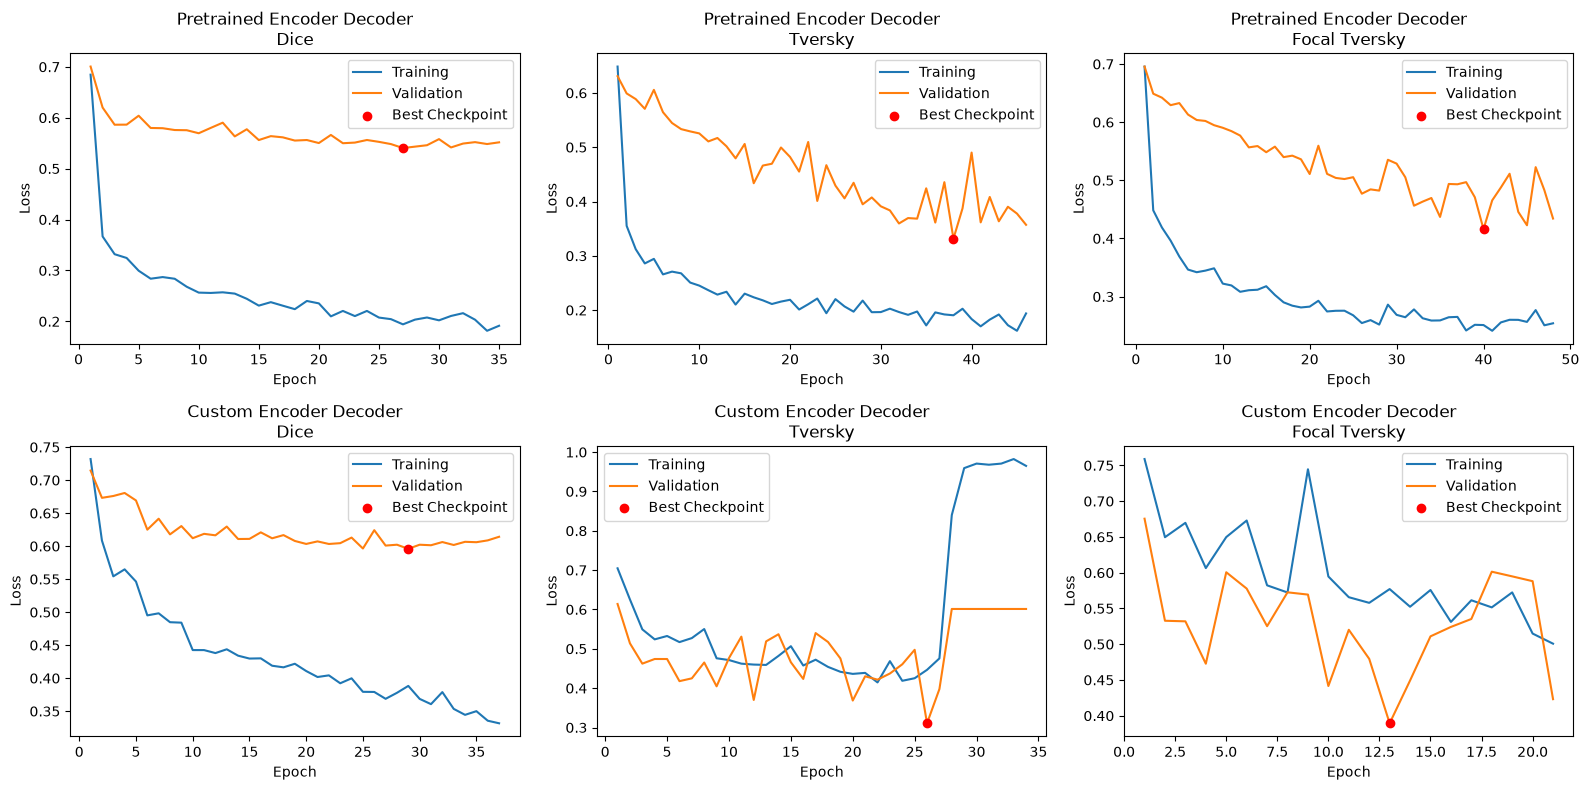

In [30]:
# Comparing 3 loss functions for custom and pretrained model.


# I saved all needed info in these csv's
history_files = {
    "Pretrained Encoder Decoder" : {
        "Dice" : history_dir / "pretrained_unet_dice.csv",
        "Tversky" : history_dir / "pretrained_unet_tversky.csv",
        "Focal Tversky" : history_dir / "pretrained_unet_focal_tversky.csv",
    },
    "Custom Encoder Decoder" : {
        "Dice" : history_dir / "custom_dice.csv",
        "Tversky" : history_dir / "custom_tversky.csv",
        "Focal Tversky" : history_dir / "custom_focal_tversky.csv",
    }
}

# Comparison table 3x2
comparison = pd.DataFrame(
    index=list(history_files),
    columns=["Dice", "Tversky", "Focal Tversky"],
    dtype=float
)
comparison.index.name = "Model"

fig, axes = plt.subplots(2,3,figsize=(16,8))
for row, (model_name, log_files) in enumerate(history_files.items()):
    for col, (loss_name, filename) in enumerate(log_files.items()):
        history = pd.read_csv(history_dir/filename)
        best_epoch = history.loc[history["val_loss"].idxmin()] # Kept model with lowest val loss
        
        comparison.loc[model_name, loss_name] = best_epoch["val_pixel_accuracy"]
        
        axis = axes[row, col]
        axis.plot(history["epoch"] + 1, history["loss"], label="Training")
        axis.plot(history["epoch"] + 1, history["val_loss"], label="Validation")
        axis.scatter(
            best_epoch["epoch"] + 1,
            best_epoch["val_loss"],
            color="red",
            label="Best Checkpoint",
            zorder=3
        )
        axis.set_title(f"{model_name}\n{loss_name}")
        axis.set_xlabel("Epoch")
        axis.set_ylabel("Loss")
        axis.legend()

print("Validation pixel accuracy at best checkpoint.")
display(comparison.round(4))
plt.tight_layout()
plt.show()

The best performing custom and pretrained models wil be selected using normal and augmented validation results. Hyperparameter tuning will be performed on the best of each group with changes assessed on the validation data. Once final config is set for each model they will be evaluated and compared on the test set.

Testing on the augmented validation and comparing against results from the normal validation will assess each models robustness to the applied augmentations/transformations. All models will be tested on the same augmented examples to make sure the comparison is fair.

In [31]:
# Normal Validation ACC, Dice and Jaccard comparison
# using val to decide best of custom and pretrained models before test

model_paths = {
    "Custom Dice": model_dir/"custom_dice.keras",
    "Custom Tversky": model_dir/"custom_tversky.keras",
    "Custom Focal Tversky": model_dir/"custom_focal_tversky.keras",
    "Pretrained Dice": model_dir/"pretrained_unet_dice.keras",
    "Pretrained Tversky": model_dir/"pretrained_unet_tversky.keras",
    "Pretrained Focal Tversky": model_dir/"pretrained_unet_focal_tversky.keras",
}

def evaluate_models(dataset, paths=model_paths):
    results = []

    for model_name, model_path in paths.items():
        model = tf.keras.models.load_model(model_path, compile=False)
        
        accuracy = tf.keras.metrics.BinaryAccuracy()
        dice_scores = []
        iou_scores = []
        positive_dice_scores = []
        empty_predictions = []
        
        # In batches
        for batch_index in range(len(dataset)):
            images,masks = dataset[batch_index]
            probabilities = model.predict_on_batch(images)
            
            # Pixel acc
            accuracy.update_state(masks, probabilities)
            
            # Convert masks to bool arrays
            predicted_masks = np.asarray(probabilities) > 0.5
            true_masks = np.asarray(masks) > 0.5
            
            # Calculating overlap
            for true_mask, predicted_mask in zip(true_masks, predicted_masks):
                true_pixels = np.count_nonzero(true_mask)
                predicted_pixels = np.count_nonzero(predicted_mask)
                
                intersection = np.count_nonzero(true_mask & predicted_mask) # AND
                union = np.count_nonzero(true_mask | predicted_mask)        # OR
                total = true_pixels + predicted_pixels
                
                # If both masks are empty, giving score of 1 - correct
                if total == 0:
                    dice = 1.0
                    iou=1.0
                else:
                    dice = 2.0 * intersection/total
                    iou = intersection / union
                    
                dice_scores.append(dice)
                iou_scores.append(iou)
                
                # Also tracking performance on only those with abnormalities
                if true_pixels > 0:
                    positive_dice_scores.append(dice)
                else:
                    empty_predictions.append(predicted_pixels == 0)
                
        
        results.append({
            "Model": model_name,
            "ACC": float(accuracy.result().numpy()),
            "DICE": np.mean(dice_scores),
            "JACCARD": np.mean(iou_scores),
            "Positive Dice": np.mean(positive_dice_scores),
            "Empty Slices Predicted Empty": np.mean(empty_predictions)
        })
        
        print(f"Finished eval: {model_name}")
        del model # Need to clean up apparently
        
    return pd.DataFrame(results).set_index("Model").sort_values("DICE", ascending=False)

Finished eval: Custom Dice
Finished eval: Custom Tversky
Finished eval: Custom Focal Tversky
Finished eval: Pretrained Dice
Finished eval: Pretrained Tversky
Finished eval: Pretrained Focal Tversky


,ACC,DICE,JACCARD,Positive Dice,Empty Slices Predicted Empty
Model,,,,,
Pretrained Tversky,0.9953,0.8173,0.7770,0.7214,0.8722
Pretrained Focal Tversky,0.9957,0.8051,0.7662,0.7380,0.8435
Custom Tversky,0.9920,0.7974,0.7602,0.5494,0.9393
Custom Dice,0.9911,0.7751,0.7382,0.6389,0.8530
Custom Focal Tversky,0.9898,0.7697,0.7306,0.5737,0.8818
Pretrained Dice,0.9958,0.7638,0.7243,0.7474,0.7732


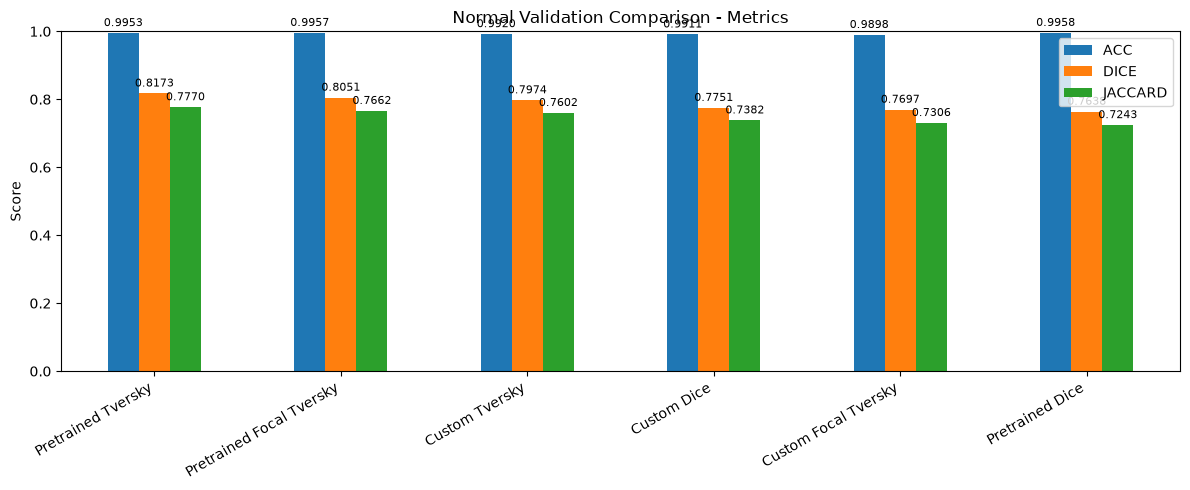

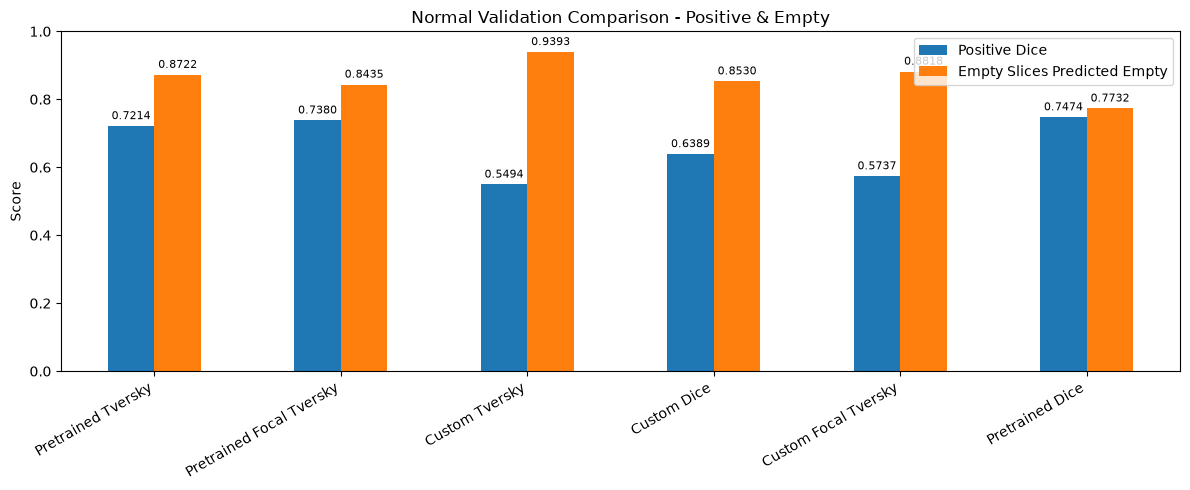

In [32]:
# Normal Validation Comparison Visuals
validation_comparison = evaluate_models(val_dataset)

# Comparison table display
display(validation_comparison.round(4))

# Plotted metrics
ax = validation_comparison[["ACC", "DICE", "JACCARD"]].plot.bar(figsize=(12,5))
for bars in ax.containers: # Add numbers on bars
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=8, rotation=0)
plt.title("Normal Validation Comparison - Metrics")
plt.ylabel("Score")
plt.xlabel("")
plt.ylim(0,1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Looking at performance on abnormalities and empty masks
ax = validation_comparison[
    ["Positive Dice", "Empty Slices Predicted Empty"]
].plot.bar(figsize=(12,5))
for bars in ax.containers: # Add numbers on bars
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=8, rotation=0)
plt.title("Normal Validation Comparison - Positive & Empty")
plt.ylabel("Score")
plt.xlabel("")
plt.ylim(0,1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# # Saving comparison for later use
# validation_comparison.to_csv(
#     history_dir/"normal_validation_comparison.csv"
# )

Pretrained Tversky got the highest overall Dice (0.8173) and Jaccard (0.7770). Pretrained Dice had the highest pixel accuracy(0.9958) and positive mask Dice (0.7475). Highest accuracy doesn't necessarily mean the best segmentation.

For the custom models, Tversky had the highest overall Dice(0.7974) and correctly predicted 93.93% of empty masks as empty. However, custom Dice was better at segmenting the abnormalities, scoring 0.6389 on masks containing abnormalities compared to 0.5494 for Tversky.

Overall Dice is heavily influenced by the large proportion of empty masks in the validation set. In this eval, an empty true mask and empty prediction mask recieve a Dice score of 1, while any predicted abnormalities on an empty true mask gives a score of 0. For this reason overall Dice is considered along with positive mask Dice (Performance on masks containing abnormalities) and empty mask performance.

There is a clear trade off here, some models are better at matching the abnormalities while others are better at avoiding predictions on empty slices.

Next the models will be compared in the same way but on the same augmented validation images before deciding which models to move forward with.

In [33]:
# Augmented validation comparisons

# Generating augmented batches to be reused for all tests
np.random.seed(24)
fixed_augmented_val = [augmented_val_dataset[batch_index] for batch_index in range(len(augmented_val_dataset))]

Finished eval: Custom Dice
Finished eval: Custom Tversky
Finished eval: Custom Focal Tversky
Finished eval: Pretrained Dice
Finished eval: Pretrained Tversky
Finished eval: Pretrained Focal Tversky


,ACC,DICE,JACCARD,Positive Dice,Empty Slices Predicted Empty
Model,,,,,
Pretrained Focal Tversky,0.9955,0.8008,0.7605,0.7486,0.8307
Custom Tversky,0.9920,0.7884,0.7511,0.5692,0.9137
Pretrained Tversky,0.9945,0.7724,0.7307,0.7097,0.8083
Custom Dice,0.9903,0.7617,0.7237,0.6412,0.8307
Custom Focal Tversky,0.9890,0.7564,0.7171,0.5761,0.8594
Pretrained Dice,0.9954,0.7332,0.6919,0.7527,0.7220


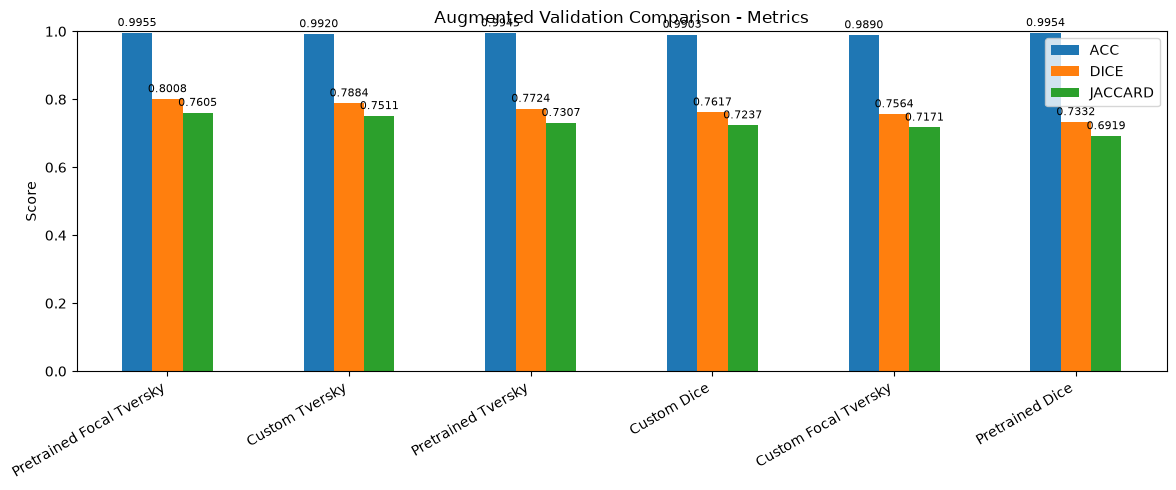

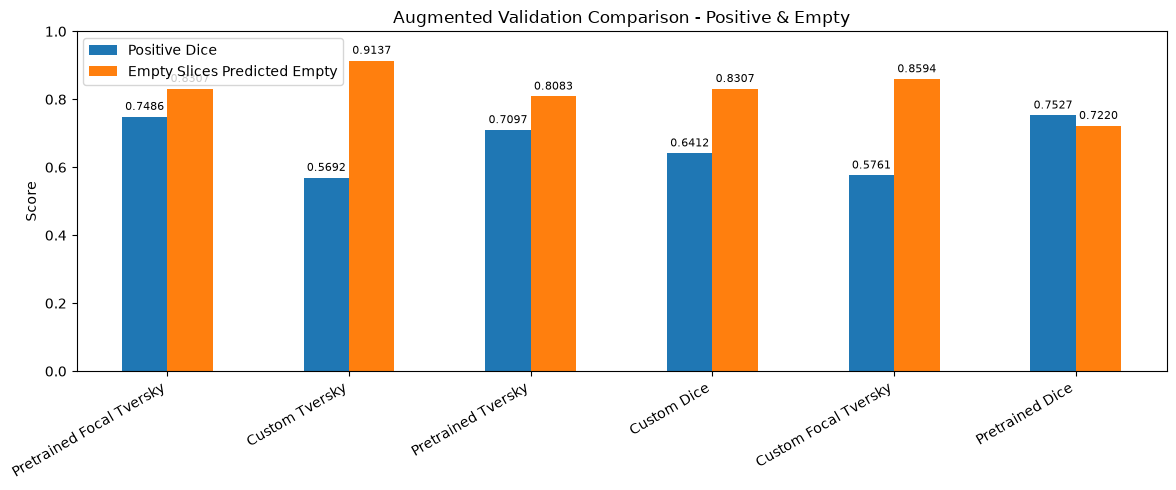

In [34]:
augmented_validation_comparison = evaluate_models(fixed_augmented_val)

# Comparison table display
display(augmented_validation_comparison.round(4))

# Plotted metrics
ax = augmented_validation_comparison[["ACC", "DICE", "JACCARD"]].plot.bar(figsize=(12,5))
for bars in ax.containers: # Add numbers on bars
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=8, rotation=0)
plt.title("Augmented Validation Comparison - Metrics")
plt.ylabel("Score")
plt.xlabel("")
plt.ylim(0,1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Looking at performance on abnormalities and empty masks
ax = augmented_validation_comparison[
    ["Positive Dice", "Empty Slices Predicted Empty"]
].plot.bar(figsize=(12,5))
for bars in ax.containers: # Add numbers on bars
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=8, rotation=0)
plt.title("Augmented Validation Comparison - Positive & Empty")
plt.ylabel("Score")
plt.xlabel("")
plt.ylim(0,1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# Saving comparison for later use
# augmented_validation_comparison.to_csv(
#     history_dir/"augmented_validation_comparison.csv"
# )

In [35]:
# Comparing normal and augmented scores
augmentation_comparison = pd.DataFrame(index=validation_comparison.index)

for metric in validation_comparison.columns:
    augmentation_comparison[f"{metric} - Normal"] = validation_comparison[metric]
    augmentation_comparison[f"{metric} - Augmented"] = augmented_validation_comparison[metric]
    
    # Calculating difference from normal to aug
    augmentation_comparison[f"{metric} - Change"] = (
        augmented_validation_comparison[metric]
        - validation_comparison[metric]
    )

# Format
formats = {
    column: "{:+.4f}" if column.endswith("Change") else "{:.4f}" # Add sign to differences
    for column in augmentation_comparison.columns
}

display_table = augmentation_comparison.copy()
for column, format_string in formats.items():
    display_table[column] = display_table[column].map(format_string.format)
display(display_table)

# augmentation_comparison.to_csv(
#     history_dir/"normal_vs_augmented_validation.csv"
# )

,ACC - Normal,ACC - Augmented,ACC - Change,DICE - Normal,DICE - Augmented,DICE - Change,JACCARD - Normal,JACCARD - Augmented,JACCARD - Change,Positive Dice - Normal,Positive Dice - Augmented,Positive Dice - Change,Empty Slices Predicted Empty - Normal,Empty Slices Predicted Empty - Augmented,Empty Slices Predicted Empty - Change
Model,,,,,,,,,,,,,,,
Pretrained Tversky,0.9953,0.9945,-0.0007,0.8173,0.7724,-0.0449,0.7770,0.7307,-0.0463,0.7214,0.7097,-0.0117,0.8722,0.8083,-0.0639
Pretrained Focal Tversky,0.9957,0.9955,-0.0002,0.8051,0.8008,-0.0043,0.7662,0.7605,-0.0057,0.7380,0.7486,+0.0106,0.8435,0.8307,-0.0128
Custom Tversky,0.9920,0.9920,-0.0000,0.7974,0.7884,-0.0090,0.7602,0.7511,-0.0091,0.5494,0.5692,+0.0198,0.9393,0.9137,-0.0256
Custom Dice,0.9911,0.9903,-0.0008,0.7751,0.7617,-0.0134,0.7382,0.7237,-0.0145,0.6389,0.6412,+0.0023,0.8530,0.8307,-0.0224
Custom Focal Tversky,0.9898,0.9890,-0.0008,0.7697,0.7564,-0.0134,0.7306,0.7171,-0.0135,0.5737,0.5761,+0.0024,0.8818,0.8594,-0.0224
Pretrained Dice,0.9958,0.9954,-0.0004,0.7638,0.7332,-0.0306,0.7243,0.6919,-0.0324,0.7474,0.7527,+0.0053,0.7732,0.7220,-0.0511


All six models had a lower overall Dice and Jaccard scores on the augmented data than on the normal data. Each model also became less reliable at leaving empty masks empty, meaning more empty masks recieved false-positive predictions. Though the drops are minimal which is to be expected.

Pretrained Focal Tversky had the highest augmented Dice (0.8009) and the smallest drop from normal validation (0.0042). Pretrained Tversky had the best normal validation Dice but dropped by 0.0449 after augmentation.

Custom Tversky had the highest overall augmented Dice from the custom models (0.7884). However, custom Dice still performed better on masks containing abnormalities, with positive mask Dice of 0.6412 compared with 0.5692 from custom Tversky.

Positive mask Dice actually increased slightly for most models. Seems the transformations produced better overlap scores, the decrease in overall Dice was mainly from worse performance on the empty slices.

The models seem to handle the transformations reasonably well. This does not prove robustness to all possible changes but gives us a fair performance comparison between the models along with the normal validation tests. From the information gathered I believe a decent model selection can be made moving forward.

## Model Selection & Tuning

Because the aim is to segment medical abnormalities I will be prioritizing positive mask Dice while considering overall Dice, Jaccard and performance on empty slides. Pixel accuracy alone is not enough becuase most of the pixels are background.

**Chosen Models:**  

**Custom Dice** is chosen from the custom models for tuning. It had the highest positive mask Dice among the custom models on both normal validation (0.6389) and augmeneted validation (0.6412). Custom Tversky had higher overall Dice and performed better on empty masks, but was worse at matching abnormalities when they were actually present. Custom Dice therefore seems to be the stronger starting point.

**Pretrained Focal Tversky** is chosen from the pretrained models for tuning. Pretrained Dice had slightly higher positive mask Dice, but Focal Tversky gave a better balance between abnormality overlap and avoiding flase positivies on empty masks. It achieved the highest overall augmented Dice (0.8009), with only a 0.0042 drop from normal validation. Its augmented positive mask Dice (0.7487) was also close to pretrained Dice (0.7527).

Because we are dealing with medical images, both missed abnormality pixels and false positives are exctremely important. Positive mask Dice measures the overlap but does not seperately measure how much abnormality was missed, so prediction examples will also need to be considered.

Both selected models will be tuned using validation data, once their configs are finalized they will be compared on the test set.

### Custom model tuning
First change will be asdding a 20% dropout at the bottleneck and learning rate reduction.

In [36]:
custom_dice_dropout_path = model_dir/"custom_dice_dropout.keras"
custom_dice_dropout_history_path = history_dir/"custom_dice_dropout.csv"

if not custom_dice_dropout_path.exists():
    tf.keras.utils.set_random_seed(24)
    
    # Same layout as before with dropout

    input_shape = (256, 256, 3)
    input_layer = Input(shape=input_shape)

    # Shrinking down
    encoding_layer = Conv2D(16, 3, activation="relu", padding="same")(input_layer)
    encoding_layer = MaxPooling2D(2)(encoding_layer)

    encoding_layer = Conv2D(32, 3, activation="relu", padding="same")(encoding_layer)
    encoding_layer = MaxPooling2D(2)(encoding_layer)

    encoding_layer = Conv2D(64, 3, activation="relu", padding="same")(encoding_layer)
    encoding_layer = MaxPooling2D(2)(encoding_layer)

    # Bottleneck at 32x32
    bottleneck_layer = Conv2D(128, 3, activation="relu", padding="same")(encoding_layer)
    # 20% dropout
    bottleneck_layer = tf.keras.layers.SpatialDropout2D(0.2)(bottleneck_layer)

    # Going back up
    decoding_layer = UpSampling2D(2)(bottleneck_layer)
    decoding_layer = Conv2D(64, 3, activation="relu", padding="same")(decoding_layer)

    decoding_layer = UpSampling2D(2)(decoding_layer)
    decoding_layer = Conv2D(32, 3, activation="relu", padding="same")(decoding_layer)

    decoding_layer = UpSampling2D(2)(decoding_layer)
    decoding_layer = Conv2D(16, 3, activation="relu", padding="same")(decoding_layer)

    # Prediction
    output_layer = Conv2D(1, 1, activation="sigmoid", padding="same")(decoding_layer)

    # Put model together
    custom_dice_dropout_model = Model(input_layer, output_layer)
    custom_dice_dropout_model.summary()
    
    # load original weights and copy to new model
    initial_model = tf.keras.models.load_model(
        model_dir/"custom_dice.keras",
        compile=False
    )
    initial_model.load_weights(model_dir/"custom_initial.weights.h5")
    custom_dice_dropout_model.set_weights(initial_model.get_weights())
    del initial_model

    custom_dice_dropout_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss=dice_loss,
        metrics=[tf.keras.metrics.BinaryAccuracy(name="pixel_accuracy")]
    )
    
    # Halve learning rate when validation loss stops improving
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=0.000001,
        verbose=1
    )
    
    # Upping early stoping from 8 to 10 for more time to get out of plateau
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=10,
        restore_best_weights=True
    )
    
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=str(custom_dice_dropout_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )
    
    csv_logger = tf.keras.callbacks.CSVLogger(str(custom_dice_dropout_history_path))
    
    # Train on same set as original model
    history_custom_dice_dropout = custom_dice_dropout_model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=50,
        callbacks=[reduce_lr, early_stopping, checkpoint, csv_logger],
        shuffle=False
    )
    custom_dice_dropout_model.load_weights(custom_dice_dropout_path) # Get best weights
else:
    # Load saved model + history
    custom_dice_dropout_model = tf.keras.models.load_model(
        custom_dice_dropout_path,
        compile=False
    )
    history_custom_dice_dropout = tf.keras.callbacks.History()
    history_custom_dice_dropout.history = (
        pd.read_csv(custom_dice_dropout_history_path)
        .drop(columns="epoch")
        .to_dict("list")
    )
    print("Loaded saved custom dice dropout model.")

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 256, 256, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 128, 128, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d               │ (None, 32, 32, 128)    │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 64, 64, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_4 (UpSampling2D)  │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 128, 128, 32)   │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_5 (UpSampling2D)  │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 256, 256, 16)   │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 256, 256, 1)    │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 194,337 (759.13 KB)

 Trainable params: 194,337 (759.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 73s 205ms/step - loss: 0.7548 - pixel_accuracy: 0.8854 - val_loss: 0.7376 - val_pixel_accuracy: 0.9886 - learning_rate: 1.0000e-04
Epoch 2/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 79s 226ms/step - loss: 0.6074 - pixel_accuracy: 0.9858 - val_loss: 0.6763 - val_pixel_accuracy: 0.9794 - learning_rate: 1.0000e-04
Epoch 3/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 69s 198ms/step - loss: 0.5551 - pixel_accuracy: 0.9877 - val_loss: 0.6693 - val_pixel_accuracy: 0.9865 - learning_rate: 1.0000e-04
Epoch 4/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 70s 200ms/step - loss: 0.5643 - pixel_accuracy: 0.9884 - val_loss: 0.6474 - val_pixel_accuracy: 0.9859 - learning_rate: 1.0000e-04
Epoch 5/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 71s 204ms/step - loss: 0.5476 - pixel_accuracy: 0.9896 - val_loss: 0.6465 - val_pixel_accuracy: 0.9874 - learning_rate: 1.0000e-04
Epoch 6/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 66s 189ms/step - loss: 0.4962 - pixel_accuracy: 0.9900 - val_loss: 0.6278 - val_pixel_accuracy: 0.9882 - 

In [37]:
# Comparing dropout model to original

comparison_paths = {
    "Original": model_dir / "custom_dice.keras",
    "Tuned": model_dir / "custom_dice_dropout.keras"
}

normal_scores = evaluate_models(val_dataset, comparison_paths)
augmented_scores = evaluate_models(fixed_augmented_val, comparison_paths)

tables = {}
for name, scores in [
    ("Normal validation", normal_scores),
    ("Augmented validation", augmented_scores)
]:
    table = scores.loc[["Original", "Tuned"]].T
    table["Change"] = table["Tuned"] - table["Original"]
    tables[name] = table
    
dropout_comparison = pd.concat(tables, names=["Dataset", "Metric"])
display(dropout_comparison.round(4))

Finished eval: Original
Finished eval: Tuned
Finished eval: Original
Finished eval: Tuned


Model                                              Original   Tuned  Change
Dataset              Metric                                                
Normal validation    ACC                             0.9911  0.9923  0.0012
                     DICE                            0.7751  0.7611 -0.0141
                     JACCARD                         0.7382  0.7207 -0.0175
                     Positive Dice                   0.6389  0.6282 -0.0107
                     Empty Slices Predicted Empty    0.8530  0.8371 -0.0160
Augmented validation ACC                             0.9903  0.9919  0.0016
                     DICE                            0.7617  0.7468 -0.0149
                     JACCARD                         0.7237  0.7062 -0.0175
                     Positive Dice                   0.6412  0.6282 -0.0130
                     Empty Slices Predicted Empty    0.8307  0.8147 -0.0160

Adding the 20% dropout at the bottlneck, learning rate reduction and longer early stopping patience did not improve the model. Positive mask dice stayed almost unchanged on normal validation and decreased slightly on augmented validation. Overall Dice and Jaccard decreased on both sets, and more empty masks received false positive predictions.

The original model is better, this configuration did not improve upon it.

I also tried another experiment increasing the batch size from 8 to 16 and selecting checkpoints using positive mask Dice instead. This slightly improved abnormality overlap but made overall Dice, Jaccard and empty mask performance worse. I ended up removing this code but it's still good to keep in mind.

The next change to be tested will be adding skip connections to the custom model making it a small custom U-Net trained from scratch.

The original model compresses the image down to 32x32 before reconstruction. Detail can be lost during this process making it harder to recover small abnormalities and accurate boundaries.

Adding skip connections between encoder and decoder layers at matching resolutions lets the decoder use earlier spatial features alongside the compressed features it was getting before.

All other configurations of the model will stay unchanged, not including the dropout from the previous test.

In [38]:
custom_skip_path = model_dir / "custom_dice_skip.keras"
custom_skip_history_path = history_dir / "custom_dice_skip.csv"

if not custom_skip_path.exists():
    tf.keras.utils.set_random_seed(24)

    input_shape = (256, 256, 3)
    input_layer = Input(shape=input_shape)

    # Shrinking down
    skip_1 = Conv2D(16, 3, activation="relu", padding="same")(input_layer)
    encoding_layer = MaxPooling2D(2)(skip_1)

    skip_2 = Conv2D(32, 3, activation="relu", padding="same")(encoding_layer)
    encoding_layer = MaxPooling2D(2)(skip_2)

    skip_3 = Conv2D(64, 3, activation="relu", padding="same")(encoding_layer)
    encoding_layer = MaxPooling2D(2)(skip_3)

    # Bottleneck at 32x32
    bottleneck_layer = Conv2D(128, 3, activation="relu", padding="same")(encoding_layer)

    # Going back up
    decoding_layer = UpSampling2D(2)(bottleneck_layer)
    decoding_layer = tf.keras.layers.Concatenate()([decoding_layer, skip_3])
    decoding_layer = Conv2D(64, 3, activation="relu", padding="same")(decoding_layer)

    decoding_layer = UpSampling2D(2)(decoding_layer)
    decoding_layer = tf.keras.layers.Concatenate()([decoding_layer, skip_2])
    decoding_layer = Conv2D(32, 3, activation="relu", padding="same")(decoding_layer)

    decoding_layer = UpSampling2D(2)(decoding_layer)
    decoding_layer = tf.keras.layers.Concatenate()([decoding_layer, skip_1])
    decoding_layer = Conv2D(16, 3, activation="relu", padding="same")(decoding_layer)

    # Prediction
    output_layer = Conv2D(1, 1, activation="sigmoid", padding="same")(decoding_layer)

    # Put model together
    custom_skip_model = Model(input_layer, output_layer)
    custom_skip_model.summary()
    
    custom_skip_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss=dice_loss,
        metrics=[tf.keras.metrics.BinaryAccuracy(name="pixel_accuracy")]
    )
    
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=8,
        restore_best_weights=True
    )
    
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=str(custom_skip_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )
    
    csv_logger = tf.keras.callbacks.CSVLogger(str(custom_skip_history_path))
    
    # Train on same set as original model
    history_custom_skip = custom_skip_model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=50,
        callbacks=[early_stopping, checkpoint, csv_logger],
        shuffle=False
    )
    custom_skip_model.load_weights(custom_skip_path) # Get best weights
else:
    # Load saved model + history
    custom_skip_model = tf.keras.models.load_model(
        custom_skip_path,
        compile=False
    )
    history_custom_skip = tf.keras.callbacks.History()
    history_custom_skip.history = (
        pd.read_csv(custom_skip_history_path)
        .drop(columns="epoch")
        .to_dict("list")
    )
    print("Loaded saved custom dice skip connection model.")

Loaded saved custom dice skip connection model.


In [39]:
# Comparing skip connection model to original

comparison_paths = {
    "Original": model_dir / "custom_dice.keras",
    "Tuned": model_dir / "custom_dice_skip.keras"
}

normal_scores = evaluate_models(val_dataset, comparison_paths)
augmented_scores = evaluate_models(fixed_augmented_val, comparison_paths)

tables = {}
for name, scores in [
    ("Normal validation", normal_scores),
    ("Augmented validation", augmented_scores)
]:
    table = scores.loc[["Original", "Tuned"]].T
    table["Change"] = table["Tuned"] - table["Original"]
    tables[name] = table
    
skip_comparison = pd.concat(tables, names=["Dataset", "Metric"])
display(skip_comparison.round(4))

Finished eval: Original
Finished eval: Tuned
Finished eval: Original
Finished eval: Tuned


Model                                              Original   Tuned  Change
Dataset              Metric                                                
Normal validation    ACC                             0.9911  0.9922  0.0011
                     DICE                            0.7751  0.7569 -0.0183
                     JACCARD                         0.7382  0.7188 -0.0194
                     Positive Dice                   0.6389  0.6502  0.0113
                     Empty Slices Predicted Empty    0.8530  0.8179 -0.0351
Augmented validation ACC                             0.9903  0.9917  0.0014
                     DICE                            0.7617  0.7382 -0.0236
                     JACCARD                         0.7237  0.6996 -0.0240
                     Positive Dice                   0.6412  0.6491  0.0079
                     Empty Slices Predicted Empty    0.8307  0.7891 -0.0415

Adding skip connections slightly improved positive mask dice from 0.6389 to 0.6502 on normal validation and from 0.6412 to 0.6491 on augmented validation. Overall Dice and Jaccard decreased on both sets, and more empty masks received false positive predictions.

The new encoder features helped the abnormality overlap a bit, but not enough to outweigh its shortcomings in all other areas. Therefore the original custom dice model will be the final selection.

### Pretrained Model Tuning
The pretrained encoder was frozen during original training, so only the decoder learned from the MRI data. The first tuning experiment for the pretrained model will be to start from our best pretrained focal tversky checkpoint and unfreeze the last few encoder blocks, allowing them to adapt to the MRI images.

Earlier encoder layers and encoder batch normalization layers will stay frozen. The learning rate will also be lowered to 0.00001.

In [40]:
finetuned_pretrained_path = model_dir/"pretrained_focal_tversky_finetuned.keras"
finetuned_pretrained_history_path = history_dir/"pretrained_focal_tversky_finetuned.csv"

if not finetuned_pretrained_path.exists():
    # Starting from best focal tversky checkpoint
    finetuned_pretrained_model = tf.keras.models.load_model(
        model_dir/"pretrained_unet_focal_tversky.keras",
        compile=False
    )
    
    # Turn training back on
    encoder = finetuned_pretrained_model.get_layer("pretrained_encoder")
    encoder.trainable = True
    
    # Unfreezing last few layers
    for layer in encoder.layers:
        layer.trainable = (
            layer.name.startswith(
                ("block_13_","block_14_","block_15_","block_16_",)
            ) and not isinstance(layer, tf.keras.layers.BatchNormalization)
        )
        
    # Recompile
    finetuned_pretrained_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
        loss=focal_tversky_loss,
        metrics=[tf.keras.metrics.BinaryAccuracy(name="pixel_accuracy")]
    )
    
    # Get starting loss from checkpoint
    starting_loss = finetuned_pretrained_model.evaluate(
        val_dataset, return_dict=True, verbose=0
    )["loss"]
    finetuned_pretrained_model.save(finetuned_pretrained_path)
    
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=8,
        restore_best_weights=True
    )
    
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=str(finetuned_pretrained_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        initial_value_threshold=starting_loss
    )
    
    csv_logger = tf.keras.callbacks.CSVLogger(str(finetuned_pretrained_history_path))
    
    history_finetuned_pretrained = finetuned_pretrained_model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=50,
        callbacks=[early_stopping, checkpoint, csv_logger],
        shuffle=False
    )
    
    finetuned_pretrained_model.load_weights(finetuned_pretrained_path)
else:
    # Load saved model + history
    finetuned_pretrained_model = tf.keras.models.load_model(
        finetuned_pretrained_path,
        compile=False
    )
    history_finetuned_pretrained = tf.keras.callbacks.History()
    history_finetuned_pretrained.history = (
        pd.read_csv(finetuned_pretrained_history_path)
        .drop(columns="epoch")
        .to_dict("list")
    )
    print("Loaded saved fine tuned pretrained focal tversky model.")

Loaded saved fine tuned pretrained focal tversky model.


In [41]:
# Comparing finetuned to original

comparison_paths = {
    "Original": model_dir / "pretrained_unet_focal_tversky.keras",
    "Tuned": model_dir / "pretrained_focal_tversky_finetuned.keras"
}

normal_scores = evaluate_models(val_dataset, comparison_paths)
augmented_scores = evaluate_models(fixed_augmented_val, comparison_paths)

tables = {}
for name, scores in [
    ("Normal validation", normal_scores),
    ("Augmented validation", augmented_scores)
]:
    table = scores.loc[["Original", "Tuned"]].T
    table["Change"] = table["Tuned"] - table["Original"]
    tables[name] = table
    
finetuned_comparison = pd.concat(tables, names=["Dataset", "Metric"])
display(finetuned_comparison.round(4))

Finished eval: Original
Finished eval: Tuned
Finished eval: Original
Finished eval: Tuned


Model                                              Original   Tuned  Change
Dataset              Metric                                                
Normal validation    ACC                             0.9957  0.9959  0.0002
                     DICE                            0.8051  0.8395  0.0344
                     JACCARD                         0.7662  0.8015  0.0354
                     Positive Dice                   0.7380  0.7263 -0.0116
                     Empty Slices Predicted Empty    0.8435  0.9042  0.0607
Augmented validation ACC                             0.9955  0.9958  0.0002
                     DICE                            0.8008  0.8339  0.0331
                     JACCARD                         0.7605  0.7944  0.0339
                     Positive Dice                   0.7486  0.7335 -0.0151
                     Empty Slices Predicted Empty    0.8307  0.8914  0.0607

Fine-tuning the encoder blocks improved overall Dice and Jaccard on both validation sets. Normal validation Dice increased from 0.8051 to 0.8395, while augmented validation Dice increased from 0.8008 to 0.8319.

The improvement seems to be from better performance on the empty masks, but positive mask Dice decreased by 0.0117 on normal validation and 0.0151 on augmented validation, showing slightly worse performance when abnormalities are actually present.

This test seems to have produced a trade-off rather than an overall improvement. Even though abnormality overlap is the main priority I am going to stick with this fine tuned model as I feel the overall increase outweighs the minor decrease in positive mask Dice.

### Final Model Selections & Comparisons

Finished eval: Custom - Dice
Finished eval: Pretrained - Finetuned Focal Tversky


,ACC,DICE,JACCARD,Positive Dice,Empty Slices Predicted Empty
Model,,,,,
Pretrained - Finetuned Focal Tversky,0.9960,0.8042,0.7714,0.6684,0.8707
Custom - Dice,0.9926,0.7362,0.7068,0.4993,0.8522


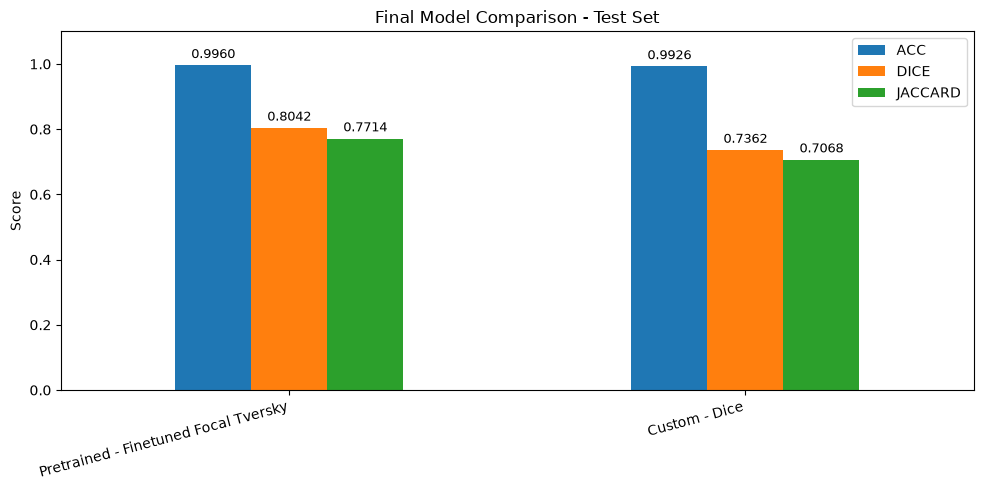

In [42]:
# Evaluating the two final selections

final_model_paths = {
    "Custom - Dice": model_dir/"custom_dice.keras",
    "Pretrained - Finetuned Focal Tversky": model_dir/"pretrained_focal_tversky_finetuned.keras"
}

final_test_comparison = evaluate_models(test_dataset, final_model_paths)
display(final_test_comparison.round(4))

# Plotting ACC, Dice and Jaccard
ax = final_test_comparison[["ACC", "DICE", "JACCARD"]].plot.bar(figsize=(10,5))
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)
plt.title("Final Model Comparison - Test Set")
plt.ylabel("Score")
plt.xlabel("")
plt.ylim(0,1.1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

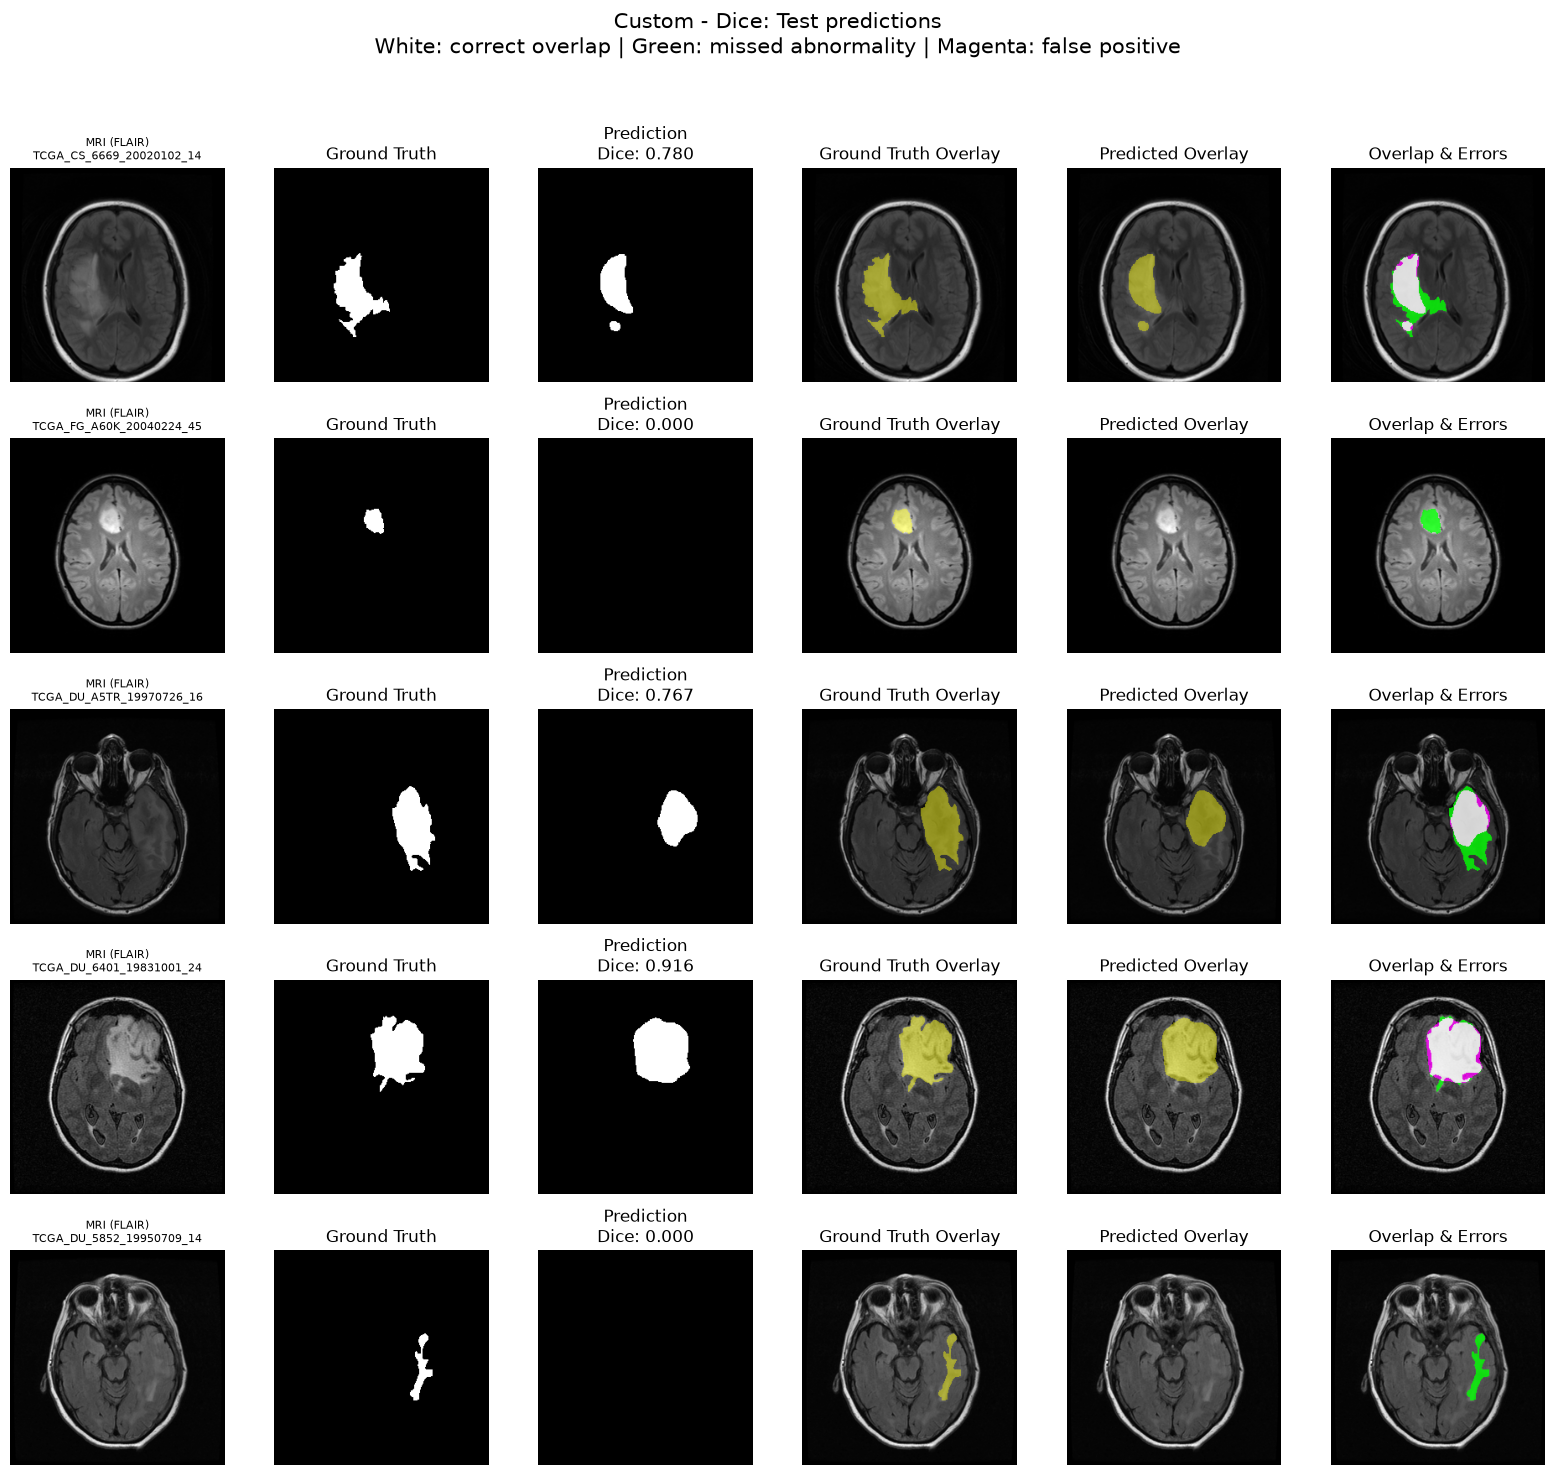

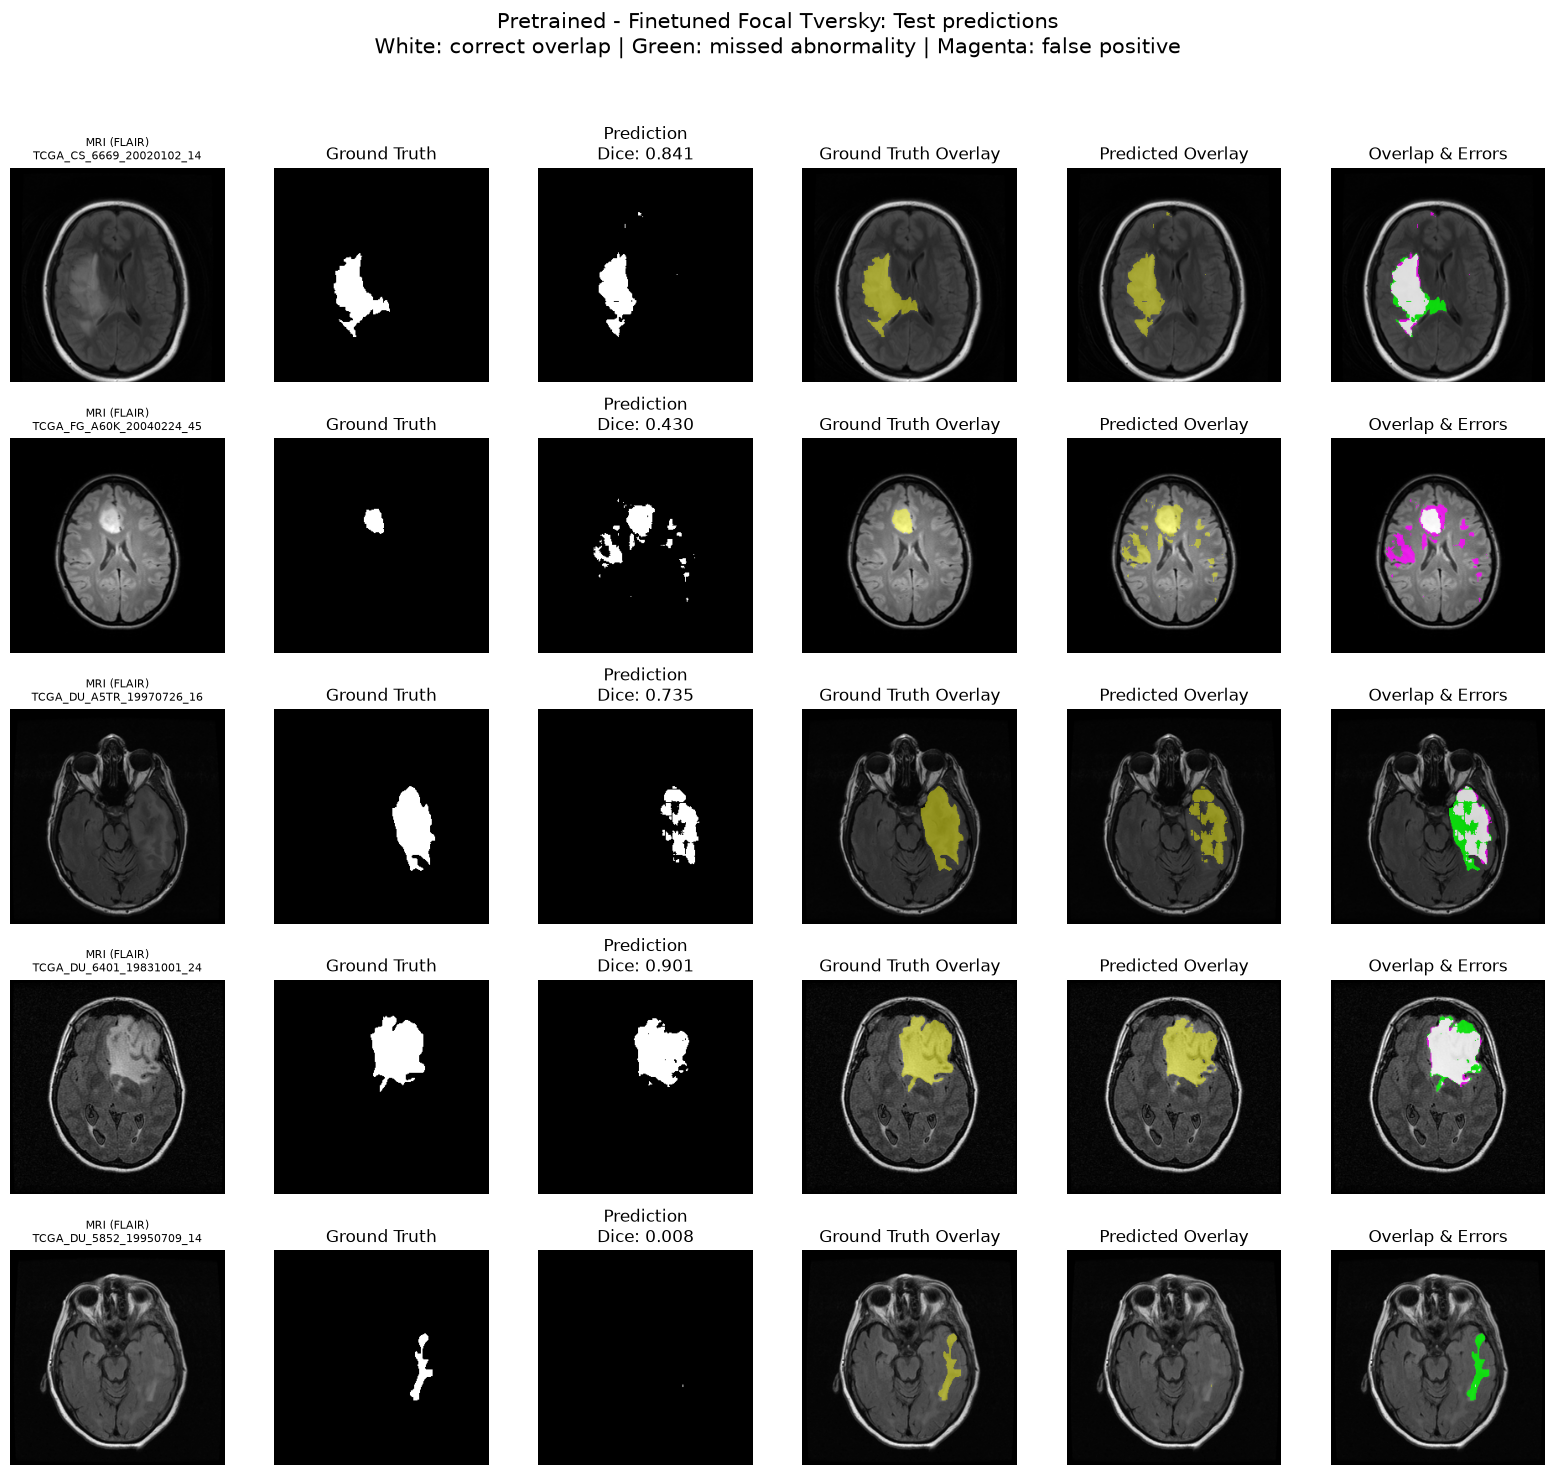

In [43]:
# Visualizing mask predictions

# Getting positive mask per patient, then grabbing five of those patients to display
examples = (
    test_df[test_df["has_abnormality"]]
    .groupby("patient_id", group_keys=False)
    .sample(n=1, random_state=24)
    .sample(n=5, random_state=24)
)

# Load examples and apply same preprocessing
images=[]
masks=[]
for _, sample in examples.iterrows():
    image, mask = load_images(sample["image_path"], sample["mask_path"])
    images.append(eval_image_gen.standardize(image.copy()))
    masks.append(mask[:, :, 0] > 0.5)
images= np.stack(images)
masks= np.stack(masks)

# Show predictions
for model_name, model_path in final_model_paths.items():
    model = tf.keras.models.load_model(model_path, compile=False)
    predictions = model.predict(images, verbose=0)[:, :, :, 0] > 0.5
    
    fig,axes = plt.subplots(5,6,figsize=(16,15))
    for row, (_,sample) in enumerate(examples.iterrows()):
        # Using FLAIR channel for greyscale display of MRI
        mri = images[row, :, :, 1] # Second channel is FLAIR
        true_mask = masks[row]
        predicted_mask = predictions[row]
        
        # DICE
        intersection = np.count_nonzero(true_mask & predicted_mask)
        total = np.count_nonzero(true_mask) + np.count_nonzero(predicted_mask)
        dice = 2.0* intersection / total
        
        # Display original, ground truth and prediction
        axes[row, 0].imshow(mri, cmap="gray")
        axes[row, 0].set_title(f"MRI (FLAIR)\n{sample['image_id']}", fontsize=8)
        axes[row, 1].imshow(true_mask, cmap="gray", vmin=0, vmax=1)
        axes[row, 1].set_title("Ground Truth")
        axes[row, 2].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
        axes[row, 2].set_title(f"Prediction\nDice: {dice:.3f}")
        
        # Hiding bg pixels so abnormality is overlaid
        true_overlay = np.ma.masked_where(~true_mask, true_mask)
        predicted_overlay = np.ma.masked_where(~predicted_mask, predicted_mask)
        
        # Ground truth on top of original image
        axes[row, 3].imshow(mri, cmap="gray")
        axes[row, 3].imshow(true_overlay, cmap="autumn", alpha=0.45, vmin=0, vmax=1)
        axes[row, 3].set_title("Ground Truth Overlay")
        
        # Prediction on top of original
        axes[row, 4].imshow(mri, cmap="gray")
        axes[row, 4].imshow(predicted_overlay, cmap="autumn", alpha=0.45, vmin=0, vmax=1)
        axes[row, 4].set_title("Predicted Overlay")
        
        # Overlaying both masks on top of original and coloring the overlap
        overlap = true_mask & predicted_mask
        missed = true_mask & ~predicted_mask
        false_positive = predicted_mask & ~true_mask
        error_overlay= np.zeros((*true_mask.shape, 4), dtype=np.float32)
        error_overlay[overlap] = [1,1,1,0.8]        # White
        error_overlay[missed] = [0,1,0,0.8]         # Green
        error_overlay[false_positive] = [1,0,1,0.8] # Magenta
        axes[row, 5].imshow(mri ,cmap="gray")
        axes[row, 5].imshow(error_overlay)
        axes[row, 5].set_title("Overlap & Errors")
        
        for axis in axes[row]:
            axis.axis("off")
    
    fig.suptitle(
        f"{model_name}: Test predictions\n"
        "White: correct overlap | Green: missed abnormality | Magenta: false positive",
        fontsize=15
    )
    plt.tight_layout(rect=[0,0,1,0.95], h_pad=2.5)
    plt.show()
    del model

The pretrained model had better overlap in the first example and identified abnormality pixels in the second example where the custom model predicted an empty mask. However, its other predictions seem to include much more false positive regions than the custom model.

The custom model performed slightly better in the third and fourth examples. Its predictions are much smoother, while the pretrained model seems to produce fragmented masks with many gaps. Both mdoels struggled with the fifth example, missing pretty much all of the abnormality.

These example images give us individual performance, across the full test set, the fine tuned pretrained Focal Tversky model achieved higher overall Dice, Jaccard and postive mask Dice, also better empty mask performance. Beating the custom model in all areas, this pretrained model wins the final selection for use in the GUI.